# 02. 입력 두 개만으로 처리 후 RNA 예측하기

여기서는 **B0 모델**을 쓴다. B0는 공개 TranSiGen 구조를 대상 HCC 세포주를 모두 뺀 다른 세포주 자료(source)로 학습한 모델이다. 이 HCC 세포주의 약물 반응은 한 번도 보지 않았다.

추론에 들어가는 것은 두 가지뿐이다.

1. 대조군 발현 X0 (978개 숫자)
2. 약물 구조를 0과 1로 적은 ECFP4 지문 (2,048개 숫자)

측정된 처리군 X1은 모델에 넣지 않는다. X1은 채점할 때 정답으로만 쓴다.
예시는 대상 HCC의 **검증(val) 약물**이다. 시험(test) 약물은 열지 않는다.

In [1]:
import os, json, sys
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
ROOT = os.environ.get("TB_ROOT", os.path.abspath(os.path.join(os.getcwd(), "..", "..")) if os.path.basename(os.getcwd()) == "transigen_adaptation_b1" else os.getcwd())
os.chdir(ROOT); sys.path.insert(0, ROOT)
pd.set_option("display.width", 160); pd.set_option("display.float_format", lambda v: f"{v:.3f}")
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8983", "font.size": 10,
                     "lines.linewidth": 2, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
MAN = "manifests/transigen_adaptation_b1"
summ = json.load(open(f"{MAN}/splits_summary.json"))["targets"]
TARGET = next(t for t in ["HUH7", "JHH7", "JHH5"] if summ.get(t, {}).get("status", "excluded") != "excluded")
SPLIT = 1
print("example target:", TARGET, "| split seed:", SPLIT)

example target: HUH7 | split seed: 1


In [2]:
import torch, inspect
from src.transigen_adaptation_b1 import tsg_adapter as T
from src.transigen_adaptation_b1.data import Data, condition_delta
from src.transigen_adaptation_b1.adapt_target import source_checkpoint
from src.transigen_adaptation_b1.evaluate import per_condition
D = Data(verify_hashes=False)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ck = source_checkpoint(42)
model, meta_ck = T.load_checkpoint(ck["checkpoint"], dev, seed=42)
print("B0 checkpoint:", ck["run_id"], "| best epoch:", ck["best_epoch"])
print("추론 함수의 인자:", list(inspect.signature(T.predict_x1_mean_path).parameters))

B0 checkpoint: source_lr0.0003_seed42_v4 | best epoch: 57
추론 함수의 인자: ['model', 'x0', 'feat', 'batch']


추론 함수의 인자에 처리군(X1)이 없다는 것을 확인했다. 이제 검증 약물들의 X0와 지문을 넣는다.

In [3]:
rows = np.sort(D.target_rows(TARGET, SPLIT, "val"))
meta = D.rows.iloc[rows]
x0 = np.asarray(D.x0[rows]); fp = D.fp[meta.drug_idx.to_numpy()]
print("입력 X0:", x0.shape, "| 입력 지문:", fp.shape, "| 지문에서 1인 자리 수(첫 약물):", int(fp[0].sum()))
x1_hat = T.predict_x1_mean_path(model, torch.tensor(x0, device=dev), torch.tensor(fp, dtype=torch.float32, device=dev)).cpu().numpy()
print("출력 X1 예측:", x1_hat.shape)
cond, d_hat = condition_delta(meta, x1_hat - x0)                  # plate 평균 -> 조건별 예측 Δ
x1 = D.target_x1(rows, TARGET, SPLIT, "val")                       # 여기서 처음 정답을 읽는다 (채점용)
_, d_true = condition_delta(meta, x1 - x0)
pc = per_condition(d_hat, d_true)
pc.insert(0, "pert_id", cond.pert_id)
print("검증 약물 수:", len(pc), "| 평균 ΔRMSE:", round(pc.delta_rmse.mean(), 4), "| 평균 조건별 ΔPearson:", round(pc.delta_pearson.mean(), 4))
print("같은 약물에서 무변화(Δ=0)의 평균 ΔRMSE:", round(float(np.sqrt((d_true ** 2).mean(1)).mean()), 4))
pc[["pert_id", "delta_rmse", "delta_pearson", "top20_direction", "truth_rms", "pred_rms"]].head(8)

입력 X0: (40, 978) | 입력 지문: (40, 2048) | 지문에서 1인 자리 수(첫 약물): 69
출력 X1 예측: (40, 978)
검증 약물 수: 19 | 평균 ΔRMSE: 1.2467 | 평균 조건별 ΔPearson: 0.247
같은 약물에서 무변화(Δ=0)의 평균 ΔRMSE: 0.8452


,pert_id,delta_rmse,delta_pearson,top20_direction,truth_rms,pred_rms
0,BRD-A19500257,1.361,0.307,0.750,1.091,1.212
1,BRD-A44244100,1.184,0.067,0.700,0.577,1.092
2,BRD-A50737080,1.617,0.432,0.850,1.726,1.219
3,BRD-A84238007,1.143,0.043,0.650,0.416,1.079
4,BRD-K13183738,1.346,0.230,0.800,0.981,1.162
5,BRD-K16410418,1.224,0.330,0.900,0.918,1.144
6,BRD-K31542390,1.304,0.284,0.600,0.985,1.141
7,BRD-K37865504,1.268,0.358,0.800,1.021,1.177


- `delta_rmse`는 약물 하나에서 978개 유전자의 예측 Δ와 정답 Δ가 평균적으로 얼마나 다른지다. 작을수록 좋다.
- `delta_pearson`은 같은 약물 안에서 유전자별 변화의 모양이 얼마나 비슷한지다. 클수록 좋다.
- `truth_rms`와 `pred_rms`는 실제 반응과 예측 반응의 크기다. 예측이 실제보다 훨씬 작으면 "거의 안 변한다"고 답한 것이다.
- 무변화 기준선과 꼭 비교한다. Δ가 원래 작은 자료에서는 아무것도 예측하지 않아도 RMSE가 낮게 나온다.

약물: BRD-A50737080 / cgk-733


,gene,정답 Δ,예측 Δ
0,HMGA2,-6.308,-3.056
1,CLIC4,-6.220,1.366
2,MAP7,-5.958,-2.046
3,APOE,-5.876,-2.248
4,TIMELESS,-5.766,-1.541
5,KIF20A,-5.685,-1.767
6,RNF167,-5.649,2.402
7,STX1A,-5.619,1.718
8,FOSL1,5.613,2.325
9,DDIT4,5.505,5.278


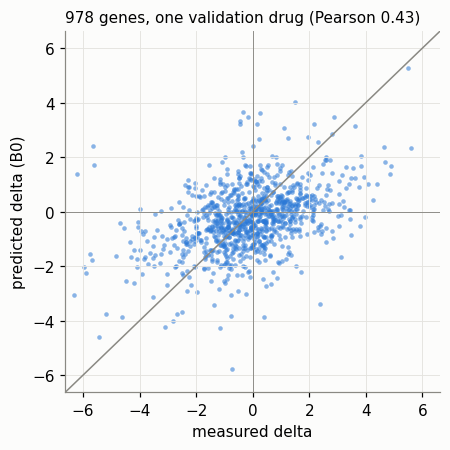

In [4]:
i = int(np.argmax(pc.truth_rms.to_numpy()))                       # 실제 반응이 가장 큰 검증 약물
top = np.argsort(-np.abs(d_true[i]))[:10]
print("약물:", cond.pert_id[i], "/", D.drugs.set_index("pert_id").cmap_name[cond.pert_id[i]])
display(pd.DataFrame({"gene": D.genes.gene_symbol.to_numpy()[top], "정답 Δ": d_true[i, top], "예측 Δ": d_hat[i, top]}))
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(d_true[i], d_hat[i], s=9, color=BLUE, alpha=0.55, linewidths=0)
lim = float(np.abs(d_true[i]).max()) * 1.05
ax.plot([-lim, lim], [-lim, lim], color=GREY, lw=1); ax.axhline(0, color=GREY, lw=0.6); ax.axvline(0, color=GREY, lw=0.6)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_xlabel("measured delta"); ax.set_ylabel("predicted delta (B0)")
ax.set_title(f"978 genes, one validation drug (Pearson {pc.delta_pearson[i]:.2f})", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 재구성과 예측을 섞지 않기

TranSiGen에는 측정된 X1을 encoder에 넣어 다시 만들어 내는 **재구성 경로**가 있다. 학습에는 필요하지만, 그 출력은 정답을 보고 만든 것이라 예측이 아니다.
이 연구의 채점은 위에서 쓴 `predict_x1_mean_path`의 출력만 사용한다.